<center><h1>Zuo_Xiyi_HW3</h1></center>
<br>
<center><font size="4">Time Series Classification Part 1: Feature Creation/Extraction</font></center>

**Name:** Xiyi Zuo
**GitHub Username:** Kiera111
**USC ID:** 9330953458


### Package imports

All dependencies are imported together so the notebook can be run sequentially from a clean kernel.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
N_BOOTSTRAP = 1000
DATA_DIR = Path("../data/AReM")
SENSOR_COLUMNS = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]
ACTIVITIES = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking",
]
STAT_NAMES = ["min", "max", "mean", "median", "std", "1st quart", "3rd quart"]
TEST_DATASETS = {
    "bending1": {1, 2},
    "bending2": {1, 2},
    "cycling": {1, 2, 3},
    "lying": {1, 2, 3},
    "sitting": {1, 2, 3},
    "standing": {1, 2, 3},
    "walking": {1, 2, 3},
}


## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

The AReM data are the Activity Recognition system based on Multisensor data fusion (AReM) data set from the UCI Machine Learning Repository. Seven folders correspond to seven activities. Each file is one instance: six time series of RSS measured by chest, left-ankle, and right-ankle sensors. The series are `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, and `var_rss23`.

The files are read from `../data/AReM`. A few files need light cleaning before the columns can be parsed:

- `bending2/dataset4.csv` is separated by spaces rather than commas.
- `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma on the last row.
- `sitting/dataset8.csv` has 479 samples. The other instances have 480.

Comment lines are skipped. A trailing comma is dropped. A space-separated row is split on whitespace. The 479-row file is kept as it is, and its features are computed from the samples that are present.


In [2]:
def load_instance(path):
    """Read one AReM instance and record any formatting that had to be repaired."""
    rows = []
    issues = set()
    for line_number, raw_line in enumerate(
        path.read_text(encoding="utf-8", errors="replace").splitlines(),
        start=1,
    ):
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue
        if "," in line:
            if line.endswith(","):
                issues.add("trailing comma")
            parts = [part.strip() for part in line.split(",") if part.strip() != ""]
        else:
            issues.add("whitespace separator")
            parts = line.split()
        if len(parts) < 7:
            raise ValueError(f"{path} line {line_number} does not have 7 fields: {raw_line!r}")
        rows.append([float(part) for part in parts[:7]])

    frame = pd.DataFrame(rows, columns=["time", *SENSOR_COLUMNS])
    if len(frame) != 480:
        issues.add(f"{len(frame)} samples")
    return frame, sorted(issues)


instances = []
cleaning_rows = []
for activity in ACTIVITIES:
    folder = DATA_DIR / activity
    paths = sorted(folder.glob("dataset*.csv"), key=lambda path: int(path.stem.replace("dataset", "")))
    for path in paths:
        dataset_id = int(path.stem.replace("dataset", ""))
        series, issues = load_instance(path)
        instances.append(
            {
                "activity": activity,
                "dataset": dataset_id,
                "path": path.relative_to(DATA_DIR).as_posix(),
                "series": series,
            }
        )
        if issues:
            cleaning_rows.append({"file": path.relative_to(DATA_DIR).as_posix(), "cleaning": ", ".join(issues)})

print(f"Loaded {len(instances)} instances from {DATA_DIR.as_posix()}")
print("Samples per instance:", sorted({len(item['series']) for item in instances}))
display(pd.DataFrame(cleaning_rows))
display(instances[0]["series"].head())


Loaded 88 instances from ../data/AReM
Samples per instance: [479, 480]


,file,cleaning
0,bending2/dataset4.csv,whitespace separator
1,cycling/dataset9.csv,trailing comma
2,cycling/dataset14.csv,trailing comma
3,sitting/dataset8.csv,479 samples


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0.0,39.25,0.43,22.75,0.43,33.75,1.3
1,250.0,39.25,0.43,23.00,0.00,33.00,0.0
2,500.0,39.25,0.43,23.25,0.43,33.00,0.0
3,750.0,39.50,0.50,23.00,0.71,33.00,0.0
4,1000.0,39.50,0.50,24.00,0.00,33.00,0.0


### (b) Test and Train Data

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, and 3 in the other five folders, are the test set. Every remaining file is the training set. This split uses the file name only. It does not use the sensor values.


In [3]:
for item in instances:
    item["split"] = (
        "test" if item["dataset"] in TEST_DATASETS[item["activity"]] else "train"
    )

split_table = (
    pd.DataFrame(
        {
            "activity": [item["activity"] for item in instances],
            "split": [item["split"] for item in instances],
        }
    )
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=ACTIVITIES, columns=["train", "test"])
)
split_table.loc["total"] = split_table.sum()
display(split_table.astype(int))


split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
total,69,19


### (c) Feature Extraction

Classification of these series uses time-domain summaries of each instance. The features below are not standardized. The later questions ask for the standard deviation of each feature, and standardization would replace those values.

#### i. Research

Time-domain features summarize the values of a series without transforming it to the frequency domain. Features commonly used for time series classification include:

- level: minimum, maximum, mean, median, and quantiles
- spread: range, variance, standard deviation, and interquartile range
- shape: skewness and kurtosis
- magnitude: root mean square and mean absolute deviation
- crossings: number of mean crossings or zero crossings
- dependence and trend: autocorrelation at selected lags, and the slope of a linear fit

This assignment uses seven of those summaries for every series: minimum, maximum, mean, median, standard deviation, first quartile, and third quartile.


#### ii. Extraction

For each of the 88 instances, each of the six series contributes seven statistics. The standard deviation is the sample standard deviation, with divisor \(n-1\). Quartiles are the 0.25 and 0.75 sample quantiles. The resulting table has 88 rows and 42 feature columns. The suffix is the series number, in the order `avg_rss12`, `var_rss12`, `avg_rss13`, `var_rss13`, `avg_rss23`, `var_rss23`.


In [4]:
def series_features(series):
    """Seven time-domain statistics for one series, in the order requested."""
    return {
        "min": series.min(),
        "max": series.max(),
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(ddof=1),
        "1st quart": series.quantile(0.25),
        "3rd quart": series.quantile(0.75),
    }


feature_rows = []
for instance_number, item in enumerate(instances, start=1):
    row = {
        "Instance": instance_number,
        "activity": item["activity"],
        "dataset": item["dataset"],
        "split": item["split"],
    }
    for series_number, column in enumerate(SENSOR_COLUMNS, start=1):
        for stat_name, value in series_features(item["series"][column]).items():
            row[f"{stat_name}{series_number}"] = value
    feature_rows.append(row)

feature_frame = pd.DataFrame(feature_rows)
feature_columns = [
    f"{stat_name}{series_number}"
    for series_number in range(1, 7)
    for stat_name in STAT_NAMES
]
feature_table = feature_frame[["Instance", *feature_columns]]

print(f"Feature table shape: {feature_table.shape}")
display(feature_table)


Feature table shape: (88, 43)


,Instance,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,median2,std2,1st quart2,3rd quart2,min3,max3,mean3,median3,std3,1st quart3,3rd quart3,min4,max4,mean4,median4,std4,1st quart4,3rd quart4,min5,max5,mean5,median5,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
0,1,37.25,45.00,40.6248,40.500,1.4770,39.2500,42.0000,0.0,1.30,0.3586,0.430,0.3226,0.0000,0.5000,4.00,29.50,19.0409,19.250,4.4630,16.0000,23.2500,0.0,7.23,0.8325,0.500,0.9657,0.0000,1.1200,27.25,38.25,34.3113,35.000,2.1884,33.0000,36.0000,0.00,1.92,0.5706,0.430,0.5829,0.0000,1.3000
1,2,38.00,45.67,42.8128,42.500,1.4355,42.0000,43.6700,0.0,1.22,0.3724,0.470,0.2892,0.0000,0.5000,2.00,29.50,20.0970,21.000,3.8937,19.0000,22.2500,0.0,5.76,0.8764,0.500,1.0473,0.0000,1.1450,27.67,38.50,33.0246,33.000,1.9953,32.0000,34.5000,0.00,3.11,0.5711,0.430,0.6010,0.0000,1.3000
2,3,35.00,47.40,43.9545,44.330,1.5588,43.0000,45.0000,0.0,1.70,0.4263,0.470,0.3387,0.0000,0.5000,6.50,29.75,22.1224,23.000,3.0309,19.7500,24.0000,0.0,4.44,0.4973,0.430,0.5507,0.0000,0.8300,29.00,38.50,35.5885,36.000,1.9996,35.3625,36.5000,0.00,1.79,0.4933,0.430,0.5135,0.0000,0.9400
3,4,33.00,47.75,42.1798,43.500,3.6707,39.1500,45.0000,0.0,3.00,0.6960,0.500,0.6309,0.0000,1.1200,8.50,30.00,22.1836,23.000,3.8105,20.5000,24.3725,0.0,5.15,0.9899,0.830,0.9537,0.4300,1.3000,20.00,38.67,33.4939,35.000,3.8494,30.4575,36.3300,0.00,2.18,0.6135,0.500,0.5243,0.0000,1.0000
4,5,33.00,45.75,41.6781,41.750,2.2435,41.3300,42.7500,0.0,2.83,0.5360,0.500,0.4055,0.4300,0.7100,3.00,28.25,19.0066,19.125,4.0871,16.5000,22.0625,0.0,6.42,0.8419,0.500,0.9288,0.4300,1.1200,23.67,37.50,29.8571,30.000,2.4110,28.4575,31.2500,0.00,1.79,0.3833,0.430,0.3892,0.0000,0.5000
5,6,37.00,48.00,43.4550,43.250,1.3861,42.5000,45.0000,0.0,1.58,0.3781,0.470,0.3156,0.0000,0.5000,5.75,27.00,15.7933,15.000,3.8476,13.0000,18.2700,0.0,10.03,0.8494,0.500,0.9958,0.4300,1.1200,8.00,33.50,23.0348,23.500,2.4889,22.2500,24.0000,0.00,5.26,0.6796,0.500,0.6225,0.4300,0.8700
6,7,36.25,48.00,43.9691,44.500,1.6184,43.3100,44.6700,0.0,1.50,0.4131,0.470,0.2631,0.4300,0.5000,1.50,26.33,15.8680,16.250,3.7424,14.2500,18.0000,0.0,5.17,0.6664,0.470,0.7890,0.0000,0.9400,11.33,30.75,22.1038,21.670,3.3183,20.5000,23.7500,0.00,2.96,0.5553,0.490,0.4878,0.0000,0.8300
7,8,12.75,51.00,24.5630,24.250,3.7375,23.1875,26.5000,0.0,6.87,0.5908,0.430,0.8374,0.0000,0.7100,0.00,25.33,19.1213,20.250,4.2996,18.0000,22.0000,0.0,6.76,0.7368,0.470,0.9270,0.0000,0.8700,10.67,30.00,23.4930,23.750,3.6938,20.5000,27.0000,0.00,4.97,0.7002,0.500,0.6937,0.4300,0.8700
8,9,0.00,42.75,27.4646,28.000,3.5836,25.5000,30.0000,0.0,7.76,0.4497,0.430,0.7672,0.0000,0.5000,7.50,35.00,20.8425,20.750,3.8263,18.0000,22.5000,0.0,5.76,0.7799,0.500,0.9044,0.0000,0.9400,0.00,33.00,17.6179,18.000,5.0536,15.0000,20.7500,0.00,6.76,1.1221,0.830,1.0123,0.4700,1.3000
9,10,21.00,50.00,32.5862,33.000,6.2381,26.1875,34.5000,0.0,9.90,0.5161,0.430,0.7900,0.0000,0.8225,0.00,28.25,13.9416,14.250,5.8833,10.0000,18.0000,0.0,7.40,0.8689,0.500,1.0270,0.4300,1.1200,5.00,33.75,20.3457,19.585,5.0324,17.6700,23.5000,0.00,13.61,1.1620,0.830,1.3330,0.4700,1.3000


#### iii. Standard Deviation

For each of the 42 columns, the point estimate is the sample standard deviation across the 88 instances. A 90% confidence interval for that standard deviation is a percentile bootstrap interval. Each replicate draws 88 instances with replacement, recomputes the sample standard deviation, and the interval is the 5th and 95th percentiles of those replicates. There are 1,000 replicates, and the random seed is 552.

`min2` and `min4` are zero for every instance, because `var_rss12` and `var_rss13` reach zero in every file. Their standard deviation is zero, and the bootstrap interval stays at zero.


In [5]:
feature_values = feature_table[feature_columns].to_numpy(dtype=float)
n_instances, n_features = feature_values.shape
point_std = feature_values.std(axis=0, ddof=1)

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_index = rng.integers(0, n_instances, size=(N_BOOTSTRAP, n_instances))
bootstrap_std = feature_values[bootstrap_index].std(axis=1, ddof=1)
ci_low = np.quantile(bootstrap_std, 0.05, axis=0)
ci_high = np.quantile(bootstrap_std, 0.95, axis=0)

std_interval = pd.DataFrame(
    {
        "feature": feature_columns,
        "std": point_std,
        "90% CI lower": ci_low,
        "90% CI upper": ci_high,
    }
)
display(std_interval)
print(
    "Intervals that contain the point estimate:",
    int(((std_interval["90% CI lower"] <= std_interval["std"]) & (std_interval["std"] <= std_interval["90% CI upper"])).sum()),
    "of",
    len(std_interval),
)


,feature,std,90% CI lower,90% CI upper
0,min1,9.5700,8.2353,10.6892
1,max1,4.3944,3.3326,5.3047
2,mean1,5.3357,4.7048,5.8863
3,median1,5.4401,4.7922,6.0093
4,std1,1.7722,1.5720,1.9438
5,1st quart1,6.1536,5.5678,6.6341
6,3rd quart1,5.1389,4.3299,5.8612
7,min2,0.0000,0.0000,0.0000
8,max2,5.0627,4.6400,5.3919
9,mean2,1.5742,1.3927,1.7044


Intervals that contain the point estimate: 42 of 42


#### iv. Select Features

The three time-domain features I keep are the **mean**, the **standard deviation**, and the **maximum**.

The table below scores each feature type by how much of its variance across instances is associated with the activity label. A higher score means the instances of different activities sit farther apart. Columns with no variation, such as `min2` and `min4`, are left out of the average because they cannot separate activities. The correlation table checks which feature types repeat the same information.


,feature,mean variance share,series used
0,mean,0.8475,6
1,median,0.8329,6
2,3rd quart,0.8317,6
3,1st quart,0.8279,6
4,std,0.6993,6
5,max,0.6725,6
6,min,0.5003,4


,min,max,mean,median,std,1st quart,3rd quart
min,1.000,0.371,0.598,0.569,-0.329,0.603,0.535
max,0.371,1.000,0.791,0.762,0.600,0.729,0.813
mean,0.598,0.791,1.000,0.992,0.392,0.981,0.985
median,0.569,0.762,0.992,1.000,0.383,0.980,0.973
std,-0.329,0.600,0.392,0.383,1.000,0.303,0.491
1st quart,0.603,0.729,0.981,0.980,0.303,1.000,0.946
3rd quart,0.535,0.813,0.985,0.973,0.491,0.946,1.000


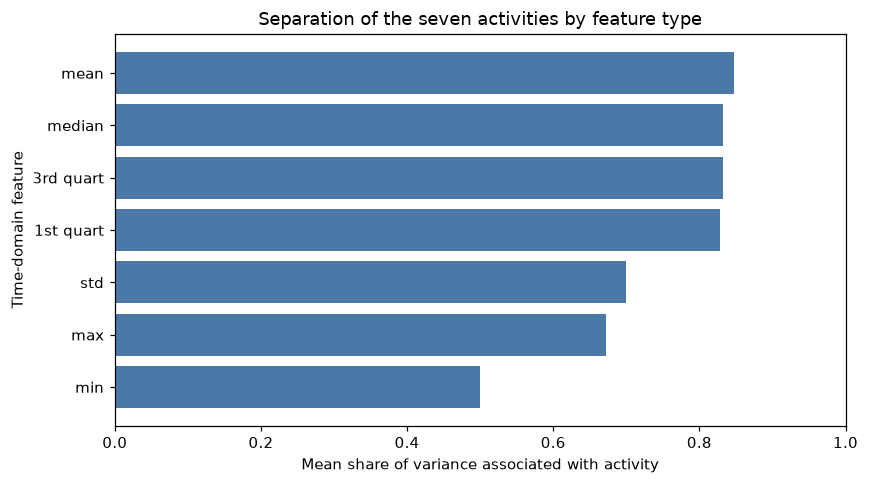

In [6]:
def activity_variance_share(column):
    """Fraction of variance associated with the activity label."""
    values = feature_frame[column].to_numpy(dtype=float)
    if np.isclose(values.std(ddof=0), 0.0):
        return np.nan
    center = values.mean()
    total = np.sum((values - center) ** 2)
    between = 0.0
    for _, group in feature_frame.groupby("activity"):
        between += len(group) * (group[column].mean() - center) ** 2
    return between / total


separation_rows = []
for stat_name in STAT_NAMES:
    shares = [activity_variance_share(f"{stat_name}{series_number}") for series_number in range(1, 7)]
    usable = [share for share in shares if pd.notna(share)]
    separation_rows.append(
        {
            "feature": stat_name,
            "mean variance share": float(np.mean(usable)),
            "series used": len(usable),
        }
    )
separation = (
    pd.DataFrame(separation_rows)
    .sort_values("mean variance share", ascending=False)
    .reset_index(drop=True)
)
display(separation)

correlation = pd.DataFrame(index=STAT_NAMES, columns=STAT_NAMES, dtype=float)
for left in STAT_NAMES:
    for right in STAT_NAMES:
        paired = []
        for series_number in range(1, 7):
            left_values = feature_frame[f"{left}{series_number}"]
            right_values = feature_frame[f"{right}{series_number}"]
            if np.isclose(left_values.std(ddof=0), 0.0) or np.isclose(right_values.std(ddof=0), 0.0):
                continue
            paired.append(left_values.corr(right_values))
        correlation.loc[left, right] = float(np.mean(paired))
display(correlation.round(3))

plot_order = separation.sort_values("mean variance share")
fig, axis = plt.subplots(figsize=(8, 4.5))
axis.barh(plot_order["feature"], plot_order["mean variance share"], color="#4C78A8")
axis.set_xlabel("Mean share of variance associated with activity")
axis.set_ylabel("Time-domain feature")
axis.set_title("Separation of the seven activities by feature type")
axis.set_xlim(0, 1)
fig.tight_layout()
plt.show()


Mean ranks first on that score. Median and the two quartiles are close behind, but each is correlated with the mean at about 0.98, so they mostly repeat the location of the series. Maximum is less redundant. It describes the peak, and it separates the activities well on the variance channels, where the minimum does not. Standard deviation has a lower separation score than the location features, but its correlation with the mean is only about 0.39, so it describes spread that the mean and the maximum do not.

Minimum is a poor third feature on this data set. The minimum of `var_rss12` and of `var_rss13` is 0 in every instance, and the minimum of `var_rss23` is almost always 0. Those columns do not distinguish activities.

I therefore use **mean**, **standard deviation**, and **maximum** from each series.


## 2. ISLR 3.7.4

The sample has \(n = 100\) observations, one predictor, and a quantitative response. Two models are fit by least squares: a linear regression, and a cubic regression

\[
Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon.
\]

The cubic model contains the linear model. Setting \(\beta_2 = \beta_3 = 0\) recovers the linear fit, so the cubic least-squares fit can always match the linear training RSS and will usually do better by using the extra terms.

### (a) Linear Train

If the true relationship is linear, the cubic model still has extra flexibility. On the training data it can use \(X^2\) and \(X^3\) to fit noise. Its training RSS is therefore smaller than the training RSS of the linear regression. The two would be equal only if the fitted quadratic and cubic coefficients were exactly zero, which does not happen in a noisy sample of this size.

### (b) Linear Test

On test data, those extra terms are a disadvantage. The true relationship has no quadratic or cubic signal, so the added flexibility increases variance without removing bias. The linear model should have the smaller test RSS.

### (c) Not Linear Train

The training comparison does not require the true curve to be linear. The cubic model is more flexible and includes the linear model as a special case, so its training RSS is again smaller than the training RSS of the linear regression.

### (d) Not Linear Testing

There is not enough information to rank the test RSS. If the true curve is close to linear, the linear model should predict better because the cubic model overfits. If the true curve is far from linear, the cubic model can have the smaller test RSS because its lower bias outweighs the extra variance. Which one wins depends on how nonlinear the relationship is.


## References

- UCI Machine Learning Repository, Activity Recognition system based on Multisensor data fusion (AReM).
- Palumbo, F., Gallicchio, C., Pucci, R., and Micheli, A. Human activity recognition using multisensor data fusion based on Reservoir Computing. *Journal of Ambient Intelligence and Smart Environments*, 2016.
- James, G., Witten, D., Hastie, T., and Tibshirani, R. *An Introduction to Statistical Learning*. Exercise 3.7.4.
- Efron, B., and Tibshirani, R. *An Introduction to the Bootstrap*. The intervals in 1(c)iii are percentile bootstrap intervals.
